# 01 - Sessionization and data model

**Business question.** The operator's raw set-top box (STB) feed is an append-only stream of
TUNE and STANDBY events: duplicated, out of order, with broken device clocks and boxes that never
report switching off. Analysts could not answer basic questions (how many people watch what, when)
without re-deriving viewing sessions each time. This notebook turns raw events into an
analysis-ready session fact table plus small dashboard aggregates.

**Production vs. this notebook.** In production the same rules run as a PySpark job
(`src/spark_sessionize.py`) over 1.5B+ records and load Snowflake (`sql/02_fact_session.sql`,
`sql/03_marts.sql`). Here the identical logic runs in pandas (`src/sessionize.py`) on a synthetic
four-week sample of 10,000 boxes.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path("../src").resolve()))
import sessionize as sz

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
RAW, PROC, FIG = Path("../data/raw"), Path("../data/processed"), Path("../reports/figures")
PROC.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)

## 1. Profile the raw feed

In [2]:
raw = sz.load_events(RAW / "stb_events.csv.gz")
channels = pd.read_csv(RAW / "channels.csv")
devices = pd.read_csv(RAW / "devices.csv")
print(f"raw events: {len(raw):,} | devices: {raw.device_id.nunique():,} | channels seen: {raw.channel_id.nunique()}")
print("event_time range:", raw.event_time.min(), "->", raw.event_time.max())
display(raw.event_type.value_counts().rename("events").to_frame())
display(raw[raw.event_type == "TUNE"].playback_mode.value_counts(normalize=True).round(4).rename("share_of_tunes").to_frame())

raw events: 1,555,814 | devices: 9,997 | channels seen: 126
event_time range: 2015-03-06 01:05:48 -> 2025-03-31 10:12:29


,events
event_type,
TUNE,1204899
STANDBY,350915


,share_of_tunes
playback_mode,
LIVE,0.7747
CATCHUP,0.0894
STARTOVER,0.056
CLOUD_DVR,0.0498
VOD,0.0301


In [3]:
dq = pd.Series({
    "exact duplicate rows": int(raw.duplicated(subset=sz.EVENT_COLS).sum()),
    "events before window (clock reset)": int((raw.event_time < sz.WINDOW_START).sum()),
    "events after window": int((raw.event_time >= sz.WINDOW_END).sum()),
    "TUNE events with no channel (VOD)": int(((raw.event_type == "TUNE") & raw.channel_id.isna()).sum()),
    "rows arriving out of time order": int((raw.event_time.diff().dt.total_seconds() < 0).sum()),
})
dq.rename("count").to_frame()

,count
exact duplicate rows,6195
events before window (clock reset),2321
events after window,0
TUNE events with no channel (VOD),36223
rows arriving out of time order,777985


Three issues need rules: duplicates (telemetry retries) are dropped; events stamped years in the
past (box clock reset to factory default) fall outside the extraction window and are dropped;
events arrive out of order, so each device's stream must be sorted before sessionizing.

## 2. Clean and sessionize

Rules (identical in pandas, PySpark and Snowflake SQL):
* a session starts at each TUNE event and ends at the device's next event (TUNE or STANDBY);
* if the next event is missing or more than 240 minutes away, the session is capped at 240
  minutes (boxes left on or unplugged never send STANDBY);
* sessions under 30 seconds are flagged as zaps (channel surfing).

In [4]:
clean, stats = sz.clean_events(raw)
sessions = sz.sessionize(clean)
stats["sessions"] = len(sessions)
pd.Series(stats).rename("rows").to_frame()

,rows
raw_events,1555814
duplicates_removed,6195
out_of_window_removed,2321
clean_events,1547298
sessions,1198334


In [5]:
ordered = sessions.sort_values(["device_id", "session_start"])
next_start = ordered.groupby("device_id").session_start.shift(-1)
checks = pd.Series({
    "one session per clean TUNE event": len(sessions) == int((clean.event_type == "TUNE").sum()),
    "no negative durations": bool((sessions.duration_sec >= 0).all()),
    "no session longer than timeout": bool(sessions.duration_sec.max() <= sz.INACTIVITY_TIMEOUT_MIN * 60),
    "no overlapping sessions per device": bool((next_start.isna() | (next_start >= ordered.session_end)).all()),
    "every session has a mode": bool(sessions.playback_mode.notna().all()),
})
assert checks.all(), checks
checks.rename("passed").to_frame()

,passed
one session per clean TUNE event,True
no negative durations,True
no session longer than timeout,True
no overlapping sessions per device,True
every session has a mode,True


,sessions,share
end_reason,,
NEXT_TUNE,859161,0.7170
STANDBY,332663,0.2776
TIMEOUT,6510,0.0054


zap share: 22.2% | median non-zap duration: 18.1 min


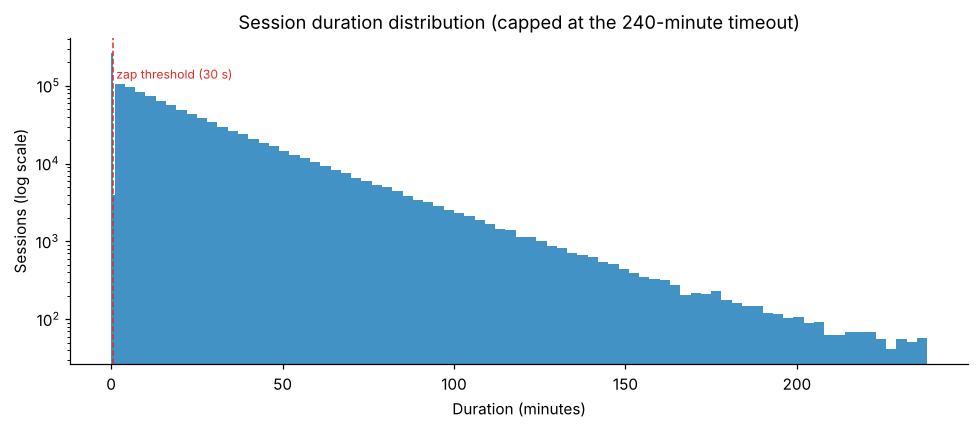

In [6]:
summary = pd.DataFrame({
    "sessions": sessions.groupby("end_reason").size(),
}).assign(share=lambda d: (d.sessions / d.sessions.sum()).round(4))
display(summary)
print(f"zap share: {sessions.is_zap.mean():.1%} | median non-zap duration: "
      f"{sessions.loc[~sessions.is_zap, 'duration_sec'].median() / 60:.1f} min")

fig, ax = plt.subplots(figsize=(9, 4))
mins = sessions.duration_sec / 60
ax.hist(mins.clip(upper=240), bins=np.r_[0, 0.5, np.arange(1, 241, 3)], color="#4292c6")
ax.set_yscale("log")
ax.axvline(0.5, color="#de2d26", ls="--", lw=1); ax.text(1.5, ax.get_ylim()[1] * 0.3, "zap threshold (30 s)", color="#de2d26", fontsize=8)
ax.set_title("Session duration distribution (capped at the 240-minute timeout)")
ax.set_xlabel("Duration (minutes)"); ax.set_ylabel("Sessions (log scale)")
fig.tight_layout(); fig.savefig(FIG / "01_session_duration.png", bbox_inches="tight"); plt.show()

## 3. Data model

Star schema used by the dashboards:

* `fact_session`: one row per session (device, channel, mode, start/end, duration, zap flag,
  end reason, content age for time-shifted viewing).
* `dim_channel`, `dim_device`: lineup and box attributes.
* `agg_hourly_channel_viewing`: viewer-minutes, sessions and unique devices per day x hour x
  channel x mode. Sessions are split across the clock hours they span so viewing lands in the
  correct hour (the pandas version of the SQL in `sql/03_marts.sql`).
* `agg_daily_kpis`: daily active devices, sessions, viewing hours by mode.

In [7]:
def split_by_hour(s: pd.DataFrame, max_hours: int = 5) -> pd.DataFrame:
    """Split sessions into clock-hour segments (a 240-minute session spans at most 5 hours)."""
    base = s.session_start.dt.floor("h")
    parts = []
    for k in range(max_hours):
        h0 = base + pd.Timedelta(hours=k)
        seg_start = np.maximum(s.session_start, h0)
        seg_end = np.minimum(s.session_end, h0 + pd.Timedelta(hours=1))
        ok = seg_end > seg_start
        parts.append(pd.DataFrame({
            "session_id": s.session_id[ok], "device_id": s.device_id[ok], "channel_id": s.channel_id[ok],
            "playback_mode": s.playback_mode[ok], "hour_start": h0[ok],
            "minutes": (seg_end - seg_start)[ok].dt.total_seconds() / 60}))
    return pd.concat(parts, ignore_index=True)

viewing = sessions[~sessions.is_zap]
seg = split_by_hour(viewing)
seg["view_date"] = seg.hour_start.dt.normalize()
seg["view_hour"] = seg.hour_start.dt.hour
agg_hourly = (seg.groupby(["view_date", "view_hour", "channel_id", "playback_mode"])
                 .agg(sessions=("session_id", "nunique"), unique_devices=("device_id", "nunique"),
                      viewer_minutes=("minutes", "sum")).reset_index())
assert abs(seg.minutes.sum() - viewing.duration_sec.sum() / 60) < 1
print(f"hour segments: {len(seg):,} | agg_hourly rows: {len(agg_hourly):,}")

daily = (sessions.assign(view_hours=sessions.duration_sec / 3600)
         .groupby("session_date")
         .agg(active_devices=("device_id", "nunique"), sessions=("session_id", "size"),
              viewing_hours=("view_hours", "sum")))
mode_daily = viewing.pivot_table(index="session_date", columns="playback_mode", values="session_id",
                                 aggfunc="size").add_prefix("sessions_")
agg_daily = daily.join(mode_daily).reset_index()
agg_daily.head(3)

hour segments: 1,366,987 | agg_hourly rows: 152,451


,session_date,active_devices,sessions,viewing_hours,sessions_CATCHUP,sessions_CLOUD_DVR,sessions_LIVE,sessions_STARTOVER,sessions_VOD
0,2025-03-03,5520,38034,13758.086389,2634,1515,22820,1697,862
1,2025-03-04,5783,40143,14705.020556,2769,1519,24292,1754,965
2,2025-03-05,5759,39831,14733.015556,2800,1491,24025,1769,919


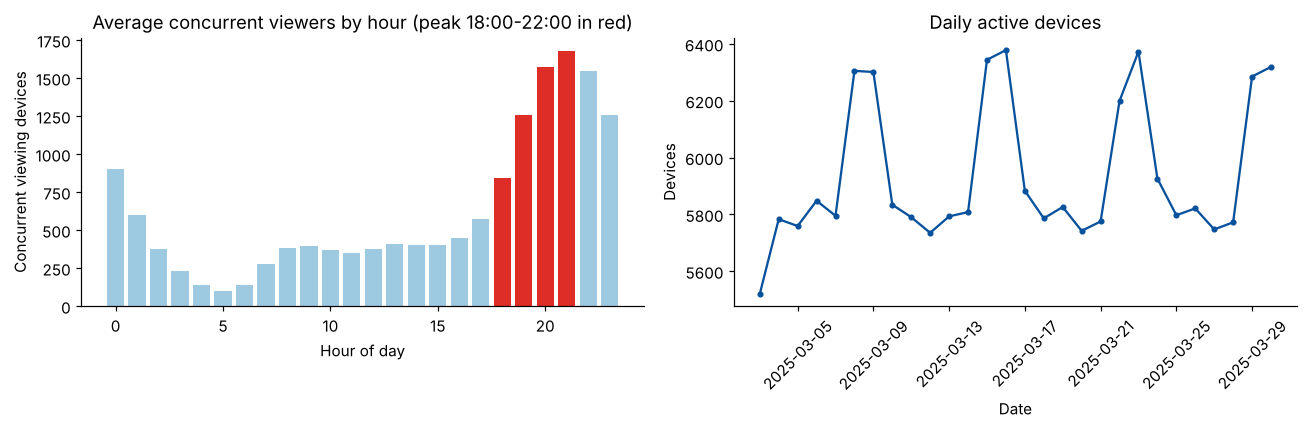

Peak (18:00-22:00) share of viewing minutes: 35.6% | mean DAU: 5,937


In [8]:
prof = seg.groupby("view_hour").minutes.sum() / seg.view_date.nunique() / 60  # concurrent viewers
dau = agg_daily.set_index("session_date").active_devices
dau = dau[dau.index < pd.Timestamp("2025-03-31")]  # drop the partial spill-over day
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
colors = ["#de2d26" if 18 <= h <= 21 else "#9ecae1" for h in prof.index]
axes[0].bar(prof.index, prof.values, color=colors)
axes[0].set_title("Average concurrent viewers by hour (peak 18:00-22:00 in red)")
axes[0].set_xlabel("Hour of day"); axes[0].set_ylabel("Concurrent viewing devices")
axes[1].plot(dau.index, dau.values, marker="o", ms=3, color="#08519c")
axes[1].set_title("Daily active devices"); axes[1].set_xlabel("Date"); axes[1].set_ylabel("Devices")
axes[1].tick_params(axis="x", rotation=45)
fig.tight_layout(); fig.savefig(FIG / "01_viewing_profile.png", bbox_inches="tight"); plt.show()
peak_share = seg[seg.view_hour.between(18, 21)].minutes.sum() / seg.minutes.sum()
print(f"Peak (18:00-22:00) share of viewing minutes: {peak_share:.1%} | mean DAU: {dau.mean():,.0f}")

## 4. Persist outputs

The full session table is cached as a gzip CSV for notebooks 02-03 (it is regenerated by this
notebook and not committed). The small aggregates and dimensions are committed.

In [9]:
sessions.to_csv(PROC / "fact_session.csv.gz", index=False, compression={"method": "gzip", "mtime": 0})
agg_hourly.to_csv(PROC / "agg_hourly_channel_viewing.csv.gz", index=False, compression={"method": "gzip", "mtime": 0})
agg_daily.assign(viewing_hours=agg_daily.viewing_hours.round(2)).to_csv(PROC / "agg_daily_kpis.csv", index=False)
channels.to_csv(PROC / "dim_channel.csv", index=False)
devices.to_csv(PROC / "dim_device.csv", index=False)
for f in sorted(PROC.glob("*")):
    print(f"{f.name:36s} {f.stat().st_size / 1e6:6.2f} MB")

agg_daily_kpis.csv                     0.00 MB
agg_hourly_channel_viewing.csv.gz      1.11 MB
dim_channel.csv                        0.00 MB
dim_device.csv                         0.41 MB
fact_session.csv.gz                   22.42 MB


## Findings

* 1,555,814 raw events from 9,997 boxes. 6,195 exact duplicates and 2,321 events with reset
  clocks (stamped 2015) were removed, leaving 1,547,298 clean events and **1,198,334 sessions**.
  All five integrity checks pass, including no overlapping sessions per device.
* 71.7% of sessions end at the next tune and 27.8% at STANDBY. 0.54% hit the 240-minute
  inactivity cap, which keeps boxes left on overnight from inflating viewing time.
* 22.2% of sessions are zaps (under 30 seconds). The median real viewing session is 18.1 minutes.
* Tune mix: live 77.5%, catch-up 8.9%, StartOver 5.6%, cloud DVR 5.0%, VOD 3.0%.
* Viewing peaks from 18:00 to 22:00, which holds 35.6% of all viewing minutes. On average 5,937
  boxes (of 10,000) are active per day over the 28 full days.
* The aggregates for dashboards (152,451 hourly channel rows and 29 daily KPI rows) total about
  1 MB, compared with 22 MB for the session table they summarize.